# Kestrel-7 RR Lyrae: exploratory analysis notebook

**Lab notebook** for the mock Kestrel-7 period–luminosity project.

> ⚠️ All data are synthetic, generated by `scripts/generate_mock_data.py`. Kestrel-7 is a fictional cluster.

**Goal:** recover pulsation periods for 42 RR Lyrae candidates, build the I-band period–luminosity (PL) relation, and estimate the cluster distance.

| Date | Entry |
|---|---|
| 2026-09-14 | Imported raw photometry, first look at data quality |
| 2026-09-21 | Lomb–Scargle period search, checked aliases |
| 2026-10-05 | Fourier fits, mean magnitudes, PL fit |
| 2026-10-19 | Distance modulus + bootstrap errors; figures for draft |

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import rrlyrae_pl as rr
%matplotlib inline

## 1. Load and inspect raw photometry
Each row is one epoch of one star in one band. `flag = 1` marks epochs the reduction pipeline identified as cosmic-ray hits or bad columns.

In [2]:
raw = pd.read_csv(ROOT / 'data/raw/kestrel7_photometry.csv')
print(raw.shape)
raw.head()

(5208, 6)


,star_id,mjd,band,mag,mag_err,flag
0,K7-V001,61212.83334,V,16.0362,0.0158,0
1,K7-V001,61215.95416,V,16.0881,0.0165,0
2,K7-V001,61219.09408,V,16.1273,0.0154,0
3,K7-V001,61220.07203,V,16.0107,0.0183,0
4,K7-V001,61221.05489,V,15.8914,0.0169,0


In [3]:
summary = raw.groupby('band').agg(n_obs=('mag','size'), median_mag=('mag','median'),
                                  median_err=('mag_err','median'), n_flagged=('flag','sum'))
summary

,n_obs,median_mag,median_err,n_flagged
band,,,,
I,2604,16.04445,0.0169,12
V,2604,16.01280,0.0166,13


In [4]:
print('Stars:', raw.star_id.nunique())
print('Time baseline (days):', round(raw.mjd.max() - raw.mjd.min(), 1))
print('Epochs per star per band:', raw.groupby(['star_id','band']).size().median())

Stars: 42
Time baseline (days): 117.9
Epochs per star per band: 62.0


*Note (09-14):* 25 flagged points, scattered across stars. Dropping them with `rr.load_photometry()`.

In [5]:
phot = rr.load_photometry()
len(raw) - len(phot)

25

## 2. Period search: one example star
Lomb–Scargle on the V-band data, searching 0.2–1.0 d.

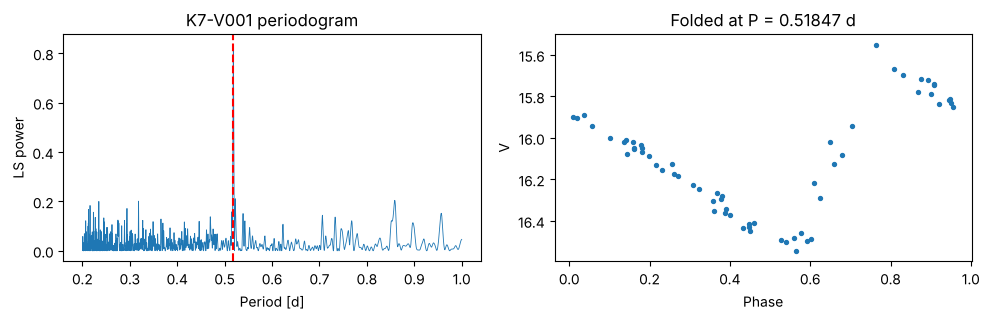

In [6]:
sid = 'K7-V001'
v = phot[(phot.star_id == sid) & (phot.band == 'V')]
P, f, power = rr.find_period(v.mjd.values, v.mag.values)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(1/f, power, lw=0.6); ax[0].axvline(P, c='r', ls='--')
ax[0].set(xlabel='Period [d]', ylabel='LS power', title=f'{sid} periodogram')
ph = (v.mjd / P) % 1
ax[1].scatter(ph, v.mag, s=8); ax[1].invert_yaxis()
ax[1].set(xlabel='Phase', ylabel='V', title=f'Folded at P = {P:.5f} d')
plt.tight_layout()

*Note (09-21):* Clear single peak. Checked 1-day aliases (P' = P/(1±P)) by eye for all stars, none preferred.

## 3. Full catalog: periods, mean magnitudes, classification

In [7]:
catalog = rr.build_catalog(phot)
catalog.head(10)

,star_id,period_d,mean_V,amp_V,rms_V,n_V,mean_I,amp_I,rms_I,n_I,type,logP_F
0,K7-V001,0.518471,16.038741,0.865381,0.044052,62,15.989516,0.545910,0.031699,61,RRab,-0.285276
1,K7-V002,0.517826,15.993545,0.884530,0.027630,61,16.045443,0.559209,0.022338,61,RRab,-0.285816
2,K7-V003,0.609183,15.993615,0.787453,0.028017,61,15.956998,0.481987,0.022351,61,RRab,-0.215253
3,K7-V004,0.586506,15.992892,0.811290,0.035030,62,15.986937,0.513447,0.022305,62,RRab,-0.231727
4,K7-V005,0.587586,16.027206,0.932674,0.023845,62,15.943506,0.570758,0.018241,62,RRab,-0.230929
5,K7-V006,0.586690,15.984168,0.798855,0.037409,62,15.977427,0.514362,0.027728,62,RRab,-0.231592
6,K7-V007,0.531477,15.976452,1.111060,0.025979,62,16.051116,0.699433,0.019877,62,RRab,-0.274515
7,K7-V008,0.570512,16.003319,0.777349,0.023638,62,16.057265,0.475403,0.019765,62,RRab,-0.243735
8,K7-V009,0.470540,16.032722,0.876687,0.024705,61,16.111355,0.564854,0.018974,61,RRab,-0.327404
9,K7-V010,0.566761,16.037180,0.625833,0.021239,61,15.980935,0.399140,0.019423,62,RRab,-0.246600


In [8]:
catalog.groupby('type')[['period_d','amp_V','mean_V','mean_I']].describe().T.round(3)

type              RRab     RRc
period_d count  28.000  14.000
         mean    0.593   0.347
         std     0.073   0.042
         min     0.471   0.276
         25%     0.545   0.317
         50%     0.587   0.349
         75%     0.639   0.379
         max     0.730   0.409
amp_V    count  28.000  14.000
         mean    0.884   0.478
         std     0.172   0.067
         min     0.519   0.356
         25%     0.790   0.464
         50%     0.871   0.490
         75%     1.016   0.512
         max     1.285   0.608
mean_V   count  28.000  14.000
         mean   15.980  15.967
         std     0.060   0.036
         min    15.846  15.905
         25%    15.954  15.943
         50%    15.985  15.971
         75%    16.011  15.976
         max    16.092  16.026
mean_I   count  28.000  14.000
         mean   15.983  16.120
         std     0.073   0.080
         min    15.801  16.006
         25%    15.954  16.097
         50%    15.981  16.112
         75%    16.046  16.150
         max    16.111  16.300

### Sanity check against simulation inputs
Because the data are mock, we can compare recovered values to the truth table.

In [9]:
truth = pd.read_csv(ROOT / 'data/raw/kestrel7_star_list.csv')
m = catalog.merge(truth, on='star_id')
print('Max fractional period error:', (abs(m.period_d - m.true_period_d)/m.true_period_d).max())
print('Type misclassifications:', (m.type != m.true_type).sum())
print('Mean I residual (recovered - true):', round((m.mean_I - m.true_mean_I).mean(), 4))

Max fractional period error: 0.0004984611432703055
Type misclassifications: 0
Mean I residual (recovered - true): -0.0102


## 4. Bailey diagram

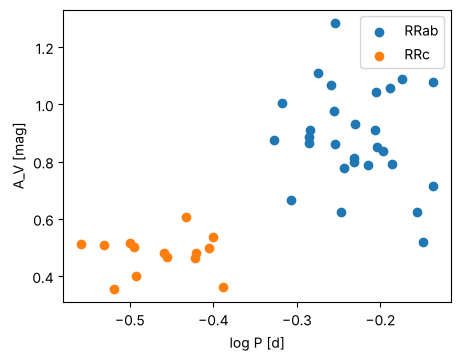

In [10]:
fig, ax = plt.subplots(figsize=(5, 3.8))
for t, g in catalog.groupby('type'):
    ax.scatter(np.log10(g.period_d), g.amp_V, label=t)
ax.set(xlabel='log P [d]', ylabel='A_V [mag]'); ax.legend()

## 5. I-band period–luminosity relation
RRc periods are fundamentalized: log P_F = log P + 0.127.

In [11]:
pl = rr.fit_pl(catalog, 'I')
{k: round(v, 4) if isinstance(v, float) else v for k, v in pl.items()}

{'band': 'I',
 'slope': np.float64(-1.2287),
 'slope_err': np.float64(0.0914),
 'intercept': np.float64(15.7026),
 'intercept_err': np.float64(0.0251),
 'scatter': np.float64(0.0427),
 'n_stars': 42}

*Note (10-05):* Free-fit slope is consistent with the adopted calibration (−1.13) within ~1σ. Keep slope fixed for the distance.

## 6. Distance modulus

In [12]:
dist = rr.distance_modulus(catalog)
{k: round(v, 4) for k, v in dist.items()}

{'mu0': np.float64(15.11),
 'mu0_stat_err': np.float64(0.0065),
 'mu0_sys_err': 0.07,
 'distance_kpc': np.float64(10.5195),
 'A_I': 0.1488}

## 7. Regenerate figures and processed outputs for the manuscript

In [13]:
catalog_out, results = rr.main(make_figs=True)

Stars analyzed: 42 (28 RRab, 14 RRc)
I-band PL slope: -1.229 ± 0.091  (scatter 0.043 mag)
Distance modulus: 15.110 ± 0.007 (stat) ± 0.07 (sys)
Distance: 10.52 kpc


## Open questions / TODO
- [ ] Test sensitivity to the reddening value (E(B−V) = 0.06–0.10)
- [ ] Add metallicity term once spectroscopy is available
- [ ] Check Oosterhoff type from ⟨P_ab⟩
- [ ] Ask co-author about blending in the cluster core